# Cryptocurrency Price Forecasting

## Model Comparison

### Objective

To compare the forecasting performance of the Prophet and HistGradientBoosting models using the same unseen test period.

The models are compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score to determine the better-performing forecasting approach.

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Load model results

prophet_results = pd.read_csv(
    "../outputs/prophet_final_results.csv"
)

hgb_results = pd.read_csv(
    "../outputs/histgradientboosting_final_results.csv"
)

print("Prophet results loaded:", prophet_results.shape)
print("HGB results loaded:", hgb_results.shape)

Prophet results loaded: (603, 4)
HGB results loaded: (603, 4)


In [3]:
# Verify matching test observations

prophet_results["ds"] = pd.to_datetime(prophet_results["ds"])
hgb_results["Date"] = pd.to_datetime(hgb_results["Date"])

dates_match = prophet_results["ds"].equals(hgb_results["Date"])
targets_match = np.allclose(
    prophet_results["y"],
    hgb_results["Target"]
)

print("Test dates match:", dates_match)
print("Actual target values match:", targets_match)

Test dates match: True
Actual target values match: True


In [4]:
# Calculate model comparison metrics

prophet_mae = mean_absolute_error(
    prophet_results["y"],
    prophet_results["predicted"]
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_results["y"],
        prophet_results["predicted"]
    )
)

prophet_r2 = r2_score(
    prophet_results["y"],
    prophet_results["predicted"]
)

hgb_mae = mean_absolute_error(
    hgb_results["Target"],
    hgb_results["Predicted"]
)

hgb_rmse = np.sqrt(
    mean_squared_error(
        hgb_results["Target"],
        hgb_results["Predicted"]
    )
)

hgb_r2 = r2_score(
    hgb_results["Target"],
    hgb_results["Predicted"]
)

comparison_results = pd.DataFrame({
    "Model": [
        "Prophet",
        "HistGradientBoosting"
    ],
    "MAE": [
        prophet_mae,
        hgb_mae
    ],
    "RMSE": [
        prophet_rmse,
        hgb_rmse
    ],
    "R2": [
        prophet_r2,
        hgb_r2
    ]
})

print(comparison_results)

                  Model          MAE         RMSE        R2
0               Prophet  3466.042792  4259.593762  0.928971
1  HistGradientBoosting  1237.200584  1765.013708  0.987805


In [5]:
# Calculate HGB improvement over Prophet

mae_improvement = (
    (prophet_mae - hgb_mae) / prophet_mae
) * 100

rmse_improvement = (
    (prophet_rmse - hgb_rmse) / prophet_rmse
) * 100

r2_improvement = (
    (hgb_r2 - prophet_r2) / prophet_r2
) * 100

print("HGB improvement over Prophet")
print("----------------------------")
print(f"MAE improvement  : {mae_improvement:.2f}%")
print(f"RMSE improvement : {rmse_improvement:.2f}%")
print(f"R² improvement   : {r2_improvement:.2f}%")

HGB improvement over Prophet
----------------------------
MAE improvement  : 64.31%
RMSE improvement : 58.56%
R² improvement   : 6.33%


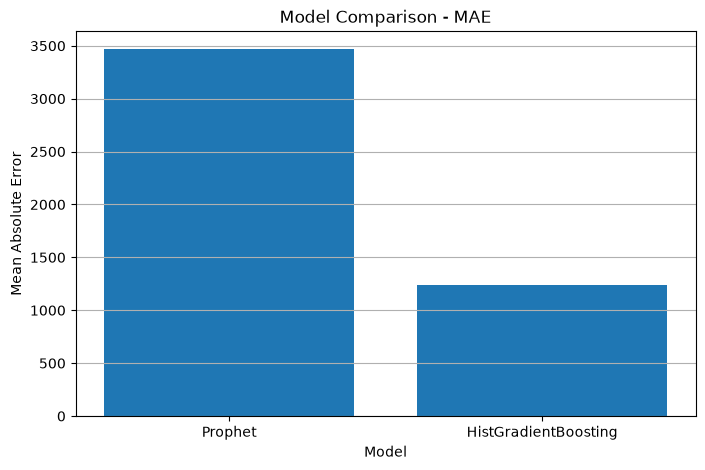

In [6]:
# Plot MAE comparison

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["MAE"]
)

plt.title("Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.grid(axis="y")

plt.savefig(
    "../outputs/graphs/15_model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

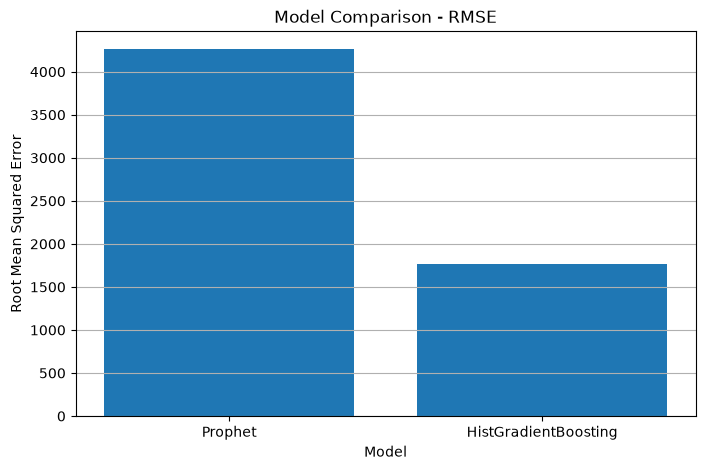

In [7]:
# Plot RMSE comparison

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["RMSE"]
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("Root Mean Squared Error")
plt.grid(axis="y")

plt.savefig(
    "../outputs/graphs/16_model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

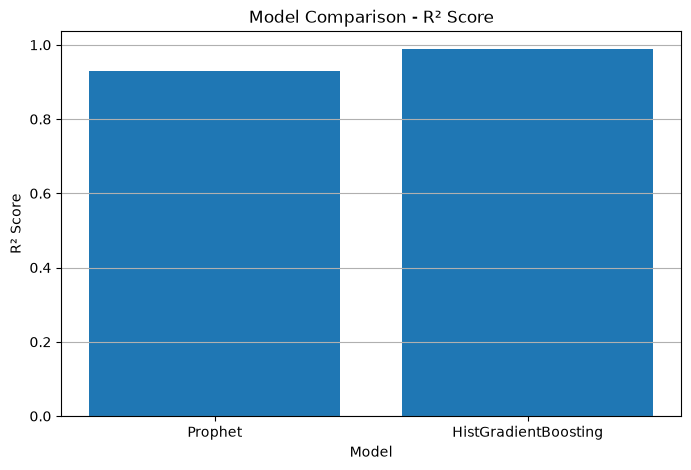

In [8]:
# Plot R2 comparison

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["R2"]
)

plt.title("Model Comparison - R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.grid(axis="y")

plt.savefig(
    "../outputs/graphs/17_model_comparison_r2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Save model comparison results

comparison_results.to_csv(
    "../outputs/model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully.")
print("File: ../outputs/model_comparison_results.csv")

Model comparison results saved successfully.
File: ../outputs/model_comparison_results.csv


## Final Model Comparison

The Prophet and HistGradientBoosting models were evaluated on the same unseen test period containing 603 observations.

### Performance Comparison

| Metric | Prophet | HistGradientBoosting |
|---|---:|---:|
| MAE | 3466.04 | **1237.20** |
| RMSE | 4259.59 | **1765.01** |
| R² | 0.92897 | **0.98781** |

### Key Findings

- HistGradientBoosting achieved a **64.31% lower MAE** than Prophet.
- HistGradientBoosting achieved a **58.56% lower RMSE** than Prophet.
- R² improved from **0.92897 to 0.98781**, representing an improvement of approximately **5.88 percentage points**.
- The lower MAE and RMSE indicate that HistGradientBoosting produced smaller prediction errors.
- The higher R² indicates that HistGradientBoosting explained a greater proportion of the variation in the target values.

### Final Conclusion

Among the two models evaluated, HistGradientBoosting performed better on the unseen test period.

The return-based HistGradientBoosting approach was particularly effective because it predicted the next-period percentage return and then converted the predicted return back into a price. This helped the model handle the large changes in cryptocurrency price levels across the dataset.

Prophet also achieved strong performance when engineered market features were incorporated as regressors, but its final errors were higher than those of HistGradientBoosting.

Therefore, based on MAE, RMSE, and R², **HistGradientBoosting is the better-performing model among the two models implemented in this project.**